# Data Quality and Preparation

This notebook examines how feature selection, missing values, discretization and anomalies affect model preparation. The demonstrations retain their original estimators and parameters.

**References:** [pandas](https://pandas.pydata.org/docs/), [scikit-learn](https://scikit-learn.org/stable/), [Feature-engine](https://feature-engine.trainindata.com/), [missingno](https://github.com/ResidentMario/missingno).

In [1]:
# Environment setup: install the packages used by this notebook in the selected kernel.
!pip install feature_engine
!pip install --upgrade scikit-learn
# !pip install optbinning
!pip install missingno

In [2]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
%matplotlib inline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
import missingno as msno
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder,StandardScaler
from feature_engine.imputation import MeanMedianImputer
import warnings
warnings.filterwarnings('ignore')
import sys
import utils as ad

## 1. Employment agreement records

Load the mixed-type contract dataset, examine its outcome distribution, and identify fields requiring encoding or imputation.

In [3]:
# Load the project dataset from its local data directory and inspect its schema.
# Load the data, which is a mixed dataset that also has missing values; the label column is class.
data = pd.read_csv('data/employment_agreements.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   f04_agreement_record_id           40 non-null     int64  
 1   f20_contract_duration             39 non-null     float64
 2   f47_wage_increase_year1           39 non-null     float64
 3   f48_wage_increase_year2           30 non-null     float64
 4   f49_wage_increase_year3           12 non-null     float64
 5   f17_cost_of_living_adjustment     24 non-null     str    
 6   f50_weekly_working_hours          37 non-null     float64
 7   f24_pension_arrangement           18 non-null     str    
 8   f33_standby_compensation          7 non-null      float64
 9   f31_shift_allowance               24 non-null     float64
 10  f21_education_support             18 non-null     str    
 11  f34_public_holiday_entitlement    38 non-null     float64
 12  f36_annual_leave     

In [4]:
# Inspect the current dataframe to confirm its structure and values.
data.head()

,f04_agreement_record_id,f20_contract_duration,f47_wage_increase_year1,f48_wage_increase_year2,f49_wage_increase_year3,f17_cost_of_living_adjustment,f50_weekly_working_hours,f24_pension_arrangement,f33_standby_compensation,f31_shift_allowance,f21_education_support,f34_public_holiday_entitlement,f36_annual_leave,f23_long_term_disability_support,f18_dental_plan_contribution,f15_bereavement_support,f19_health_plan_contribution,f28_agreement_rating,f16_agreement_outcome
0,0,1.0,5.0,NaN,NaN,NaN,40.0,NaN,NaN,2.0,NaN,11.0,average,NaN,NaN,yes,NaN,3.5,good
1,1,2.0,4.5,5.8,NaN,NaN,35.0,ret_allw,NaN,NaN,yes,11.0,below-average,NaN,full,NaN,full,5.0,good
2,2,NaN,NaN,NaN,NaN,NaN,38.0,empl_contr,NaN,5.0,NaN,11.0,generous,yes,half,yes,half,4.0,good
3,3,3.0,3.7,4.0,5.0,tc,NaN,NaN,NaN,NaN,yes,NaN,NaN,NaN,NaN,yes,NaN,3.5,good
4,4,3.0,4.5,4.5,5.0,NaN,40.0,NaN,NaN,NaN,NaN,12.0,average,NaN,half,yes,half,5.0,good


In [5]:
# Inspect or update the intermediate result produced by the preceding step.
# The class label column values distribution.
data['f16_agreement_outcome'].value_counts()

f16_agreement_outcome
good    26
bad     14
Name: count, dtype: int64

In [6]:
# Separate predictors from the target using the original column-selection rule.
# Separate the response label from the predictor features.
y = data['f16_agreement_outcome']
X = data[data.columns.difference(['f16_agreement_outcome'])]
# Typically we should split data into training and testing,.
# But this dataset is too small, so we will simply use crossvalidation.

### Cross-validation as a reference point

Use the helper in `utils.py` to summarize the mean and variability of classification metrics across folds. Cross-validation can reveal instability; it does not replace a leakage check.

### Baseline models and leakage checks

Prepare the data for a decision-tree baseline. A strikingly high score can arise from a proxy for the target, so the notebook also compares the model after removing a potentially leaky field. Retain the original data splitting and fitting steps for comparability.

In [7]:
# Inspect the current dataframe to confirm its structure and values.
# Fit the estimator using the designated training observations.
dt_X = X.copy()
# Retrieve the regular numeric columns names.
num_cols = list(dt_X.select_dtypes(include=['int64','float64']).columns)
# Retrive the regular object columns names.
obj_cols = list(dt_X.select_dtypes(include=['object']).columns)
# Replace missing/nan values with 0 for numerical columns.
dt_X[num_cols] = dt_X[num_cols].apply(
      lambda col: col.fillna(0, axis=0)
  )
# Replace missing/nan values with '?' for object columns.
dt_X[obj_cols] = dt_X[obj_cols].apply(
      lambda col: col.fillna('?', axis=0).astype(str)
  )
# Encode the object columns using an OrdinalEncoder instance.
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
dt_X.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   f04_agreement_record_id           40 non-null     int64  
 1   f15_bereavement_support           40 non-null     float64
 2   f17_cost_of_living_adjustment     40 non-null     float64
 3   f18_dental_plan_contribution      40 non-null     float64
 4   f19_health_plan_contribution      40 non-null     float64
 5   f20_contract_duration             40 non-null     float64
 6   f21_education_support             40 non-null     float64
 7   f23_long_term_disability_support  40 non-null     float64
 8   f24_pension_arrangement           40 non-null     float64
 9   f28_agreement_rating              40 non-null     float64
 10  f31_shift_allowance               40 non-null     float64
 11  f33_standby_compensation          40 non-null     float64
 12  f34_public_holiday_en

In [8]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Create an instance of the DT classifier leaving.
# All hyperparameters to default values except random_state.
dt_clf = DecisionTreeClassifier(random_state=43)
# Crossvalidate on the encoded train portion using the custom function.
ad.report_classification_cv(dt_X, y, dt_clf)

Mean Accuracy is 100.00 +/- 0.00
Mean Precision is 100.00 +/- 0.00
Mean Recall is 100.00 +/- 0.00
Mean F-score is 100.00 +/- 0.00


[Text(0.5, 0.75, 'f28_agreement_rating <= 3.25\ngini = 0.455\nsamples = 40\nvalue = [14, 26]\nclass = good'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 14\nvalue = [14, 0]\nclass = bad'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 26\nvalue = [0, 26]\nclass = good'),
 Text(0.625, 0.5, '  False')]

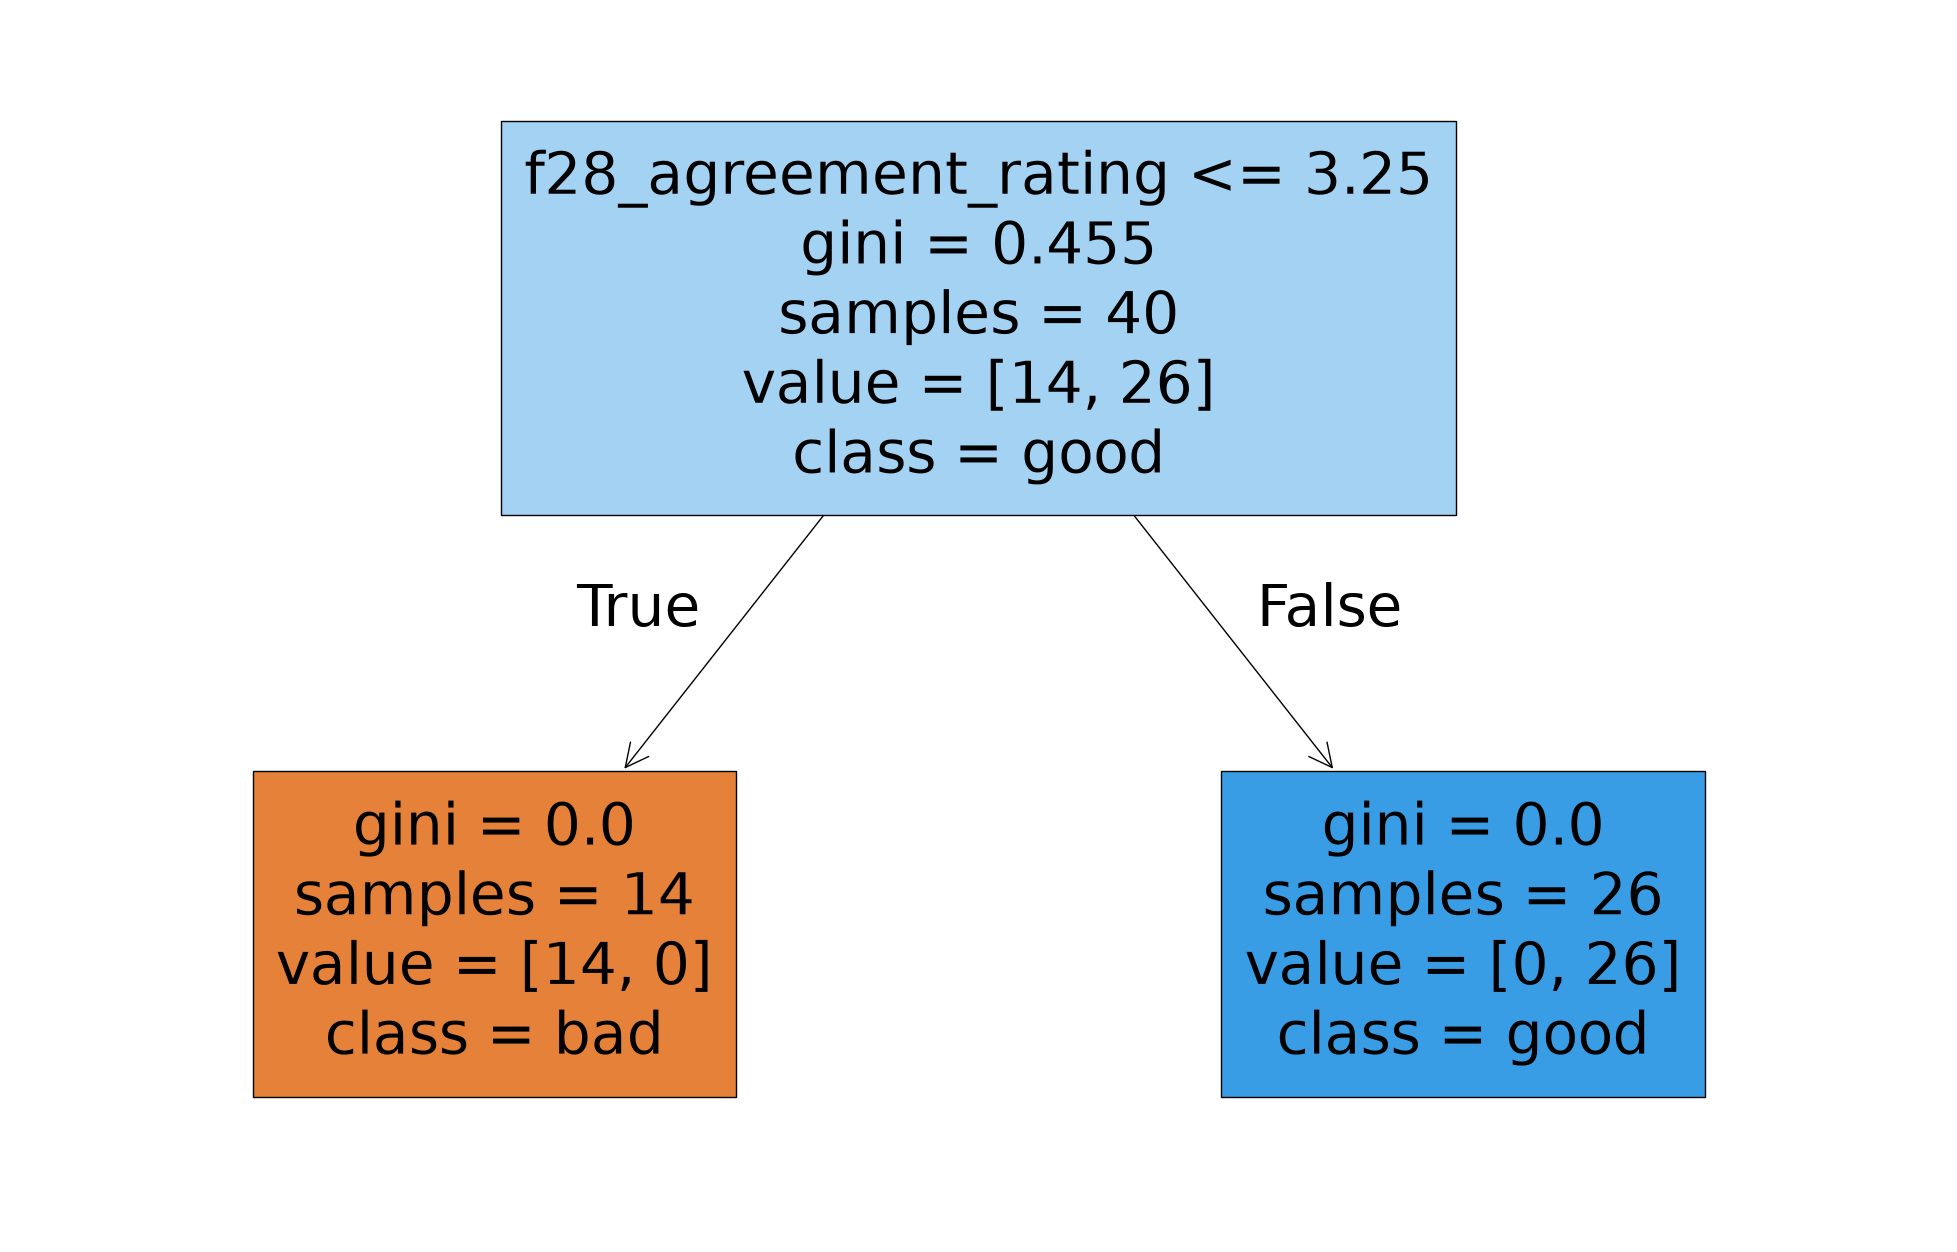

In [9]:
# Fit the configured model with its existing parameters.
# A perfect score merits a check for leakage or target-proxy variables.
# So the dataset should be explored further or understand the features definitions.
# Or we could look at the tree model.
dt_clf.fit(dt_X, y)
plt.figure(figsize=(25, 16))
plot_tree(dt_clf,filled=True,feature_names=list(dt_X.columns),class_names=dt_clf.classes_)

In [10]:
# Inspect the current dataframe to confirm its structure and values.
# Keep this transformation within training folds to limit information leakage.
data = data.drop(['f28_agreement_rating'], axis=1)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   f04_agreement_record_id           40 non-null     int64  
 1   f20_contract_duration             39 non-null     float64
 2   f47_wage_increase_year1           39 non-null     float64
 3   f48_wage_increase_year2           30 non-null     float64
 4   f49_wage_increase_year3           12 non-null     float64
 5   f17_cost_of_living_adjustment     24 non-null     str    
 6   f50_weekly_working_hours          37 non-null     float64
 7   f24_pension_arrangement           18 non-null     str    
 8   f33_standby_compensation          7 non-null      float64
 9   f31_shift_allowance               24 non-null     float64
 10  f21_education_support             18 non-null     str    
 11  f34_public_holiday_entitlement    38 non-null     float64
 12  f36_annual_leave     

In [11]:
# Separate predictors from the target using the original column-selection rule.
# Separate the response label from the predictor features.
y = data['f16_agreement_outcome']
X = data[data.columns.difference(['f16_agreement_outcome'])]

In [12]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Fit the estimator using the designated training observations.
dt_X = X.copy()
# Retrieve the regular numeric columns names.
num_cols = list(dt_X.select_dtypes(include=['int64','float64']).columns)
# Retrive the regular object columns names.
obj_cols = list(dt_X.select_dtypes(include=['object']).columns)
# Replace missing/nan values with 0 for numerical columns.
dt_X[num_cols] = dt_X[num_cols].apply(
      lambda col: col.fillna(0, axis=0)
  )
# Replace missing/nan values with '?' for object columns.
dt_X[obj_cols] = dt_X[obj_cols].apply(
      lambda col: col.fillna('?', axis=0).astype(str)
  )
# Encode the object columns using an OrdinalEncoder instance.
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
ad.report_classification_cv(dt_X, y, dt_clf)

Mean Accuracy is 70.00 +/- 12.75
Mean Precision is 59.13 +/- 24.37
Mean Recall is 67.33 +/- 19.25
Mean F-score is 61.15 +/- 21.30


## 2. Identify useful features

Review low-variance and constant fields, identifier-like columns, and correlated measurements. Feature removal is a modeling decision: low variance alone does not prove a variable is irrelevant. A separate synthetic dataset illustrates correlation-based filtering.

In [13]:
# Continue the analysis using the original transformation and model parameters.
# 1. drop numerical columns with low std, let's say less than 3 or high std > 400.
# Across all columns --> should be used with caution!!!
low_mask = X[num_cols].std()[X[num_cols].std() < 3].index
high_mask = X[num_cols].std()[X[num_cols].std() > 400].index
mask = low_mask.union(high_mask)
print(mask)

Index(['f20_contract_duration', 'f34_public_holiday_entitlement',
       'f47_wage_increase_year1', 'f48_wage_increase_year2',
       'f49_wage_increase_year3', 'f50_weekly_working_hours'],
      dtype='str')


In [14]:
# Inspect the current dataframe to confirm its structure and values.
# The above technique can remove most of numeric columns which may still hold useful patterns.
# The correct approach is to investigate the summary statistics/plots of each attribute and then decide:
# Based on plots or summary stats, e.g., range of values, percentiles, etc.
# Output summary statistics for all attributes.
data.describe()

,f04_agreement_record_id,f20_contract_duration,f47_wage_increase_year1,f48_wage_increase_year2,f49_wage_increase_year3,f50_weekly_working_hours,f33_standby_compensation,f31_shift_allowance,f34_public_holiday_entitlement
count,40.000000,39.000000,39.000000,30.000000,12.000000,37.000000,7.000000,24.000000,38.000000
mean,19.500000,2.102564,3.620513,3.913333,3.766667,37.810811,6.142857,4.583333,11.105263
std,11.690452,0.753758,1.331438,1.280822,1.415070,2.716593,4.845223,4.754098,1.371318
min,0.000000,1.000000,2.000000,2.000000,2.000000,27.000000,2.000000,0.000000,9.000000
25%,9.750000,2.000000,2.500000,2.625000,2.250000,37.000000,2.000000,3.000000,10.000000
50%,19.500000,2.000000,3.500000,4.000000,4.600000,38.000000,4.000000,4.000000,11.000000
75%,29.250000,3.000000,4.500000,4.500000,5.000000,40.000000,10.000000,5.000000,12.000000
max,39.000000,3.000000,6.900000,7.000000,5.100000,40.000000,13.000000,25.000000,15.000000


In [15]:
# Evaluate the current estimator using the configured cross-validation strategy.
# E.g., we can try to drop duration since it appears to have the little variability.
# And crossvalidate without it to assess the impact, since it may still hold useful information.
ad.report_classification_cv(dt_X.drop(['f20_contract_duration'], axis=1), y, dt_clf)

Mean Accuracy is 70.00 +/- 6.12
Mean Precision is 56.83 +/- 20.90
Mean Recall is 66.00 +/- 13.56
Mean F-score is 59.38 +/- 17.08


<Axes: xlabel='f20_contract_duration'>

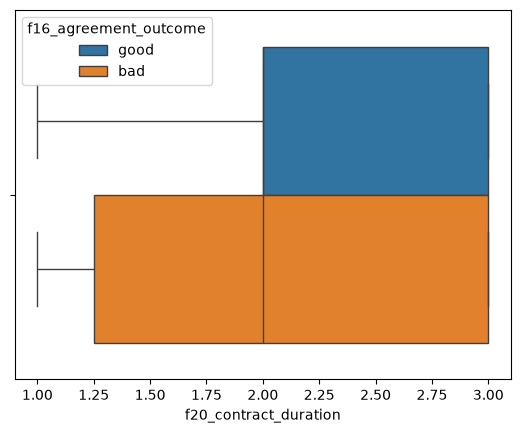

In [16]:
# Visualize the current measurements or fitted results for interpretation.
sns.boxplot(data=data, x='f20_contract_duration', hue='f16_agreement_outcome')

In [17]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 2. drop columns where the values are the same in every row.
# There are none in this dataset, but below is the relevant code.
mask = X.columns[X.nunique() == 1]
print(mask)
ad.report_classification_cv(dt_X.drop(mask, axis=1), y, dt_clf)

Index([], dtype='str')
Mean Accuracy is 70.00 +/- 12.75
Mean Precision is 59.13 +/- 24.37
Mean Recall is 67.33 +/- 19.25
Mean F-score is 61.15 +/- 21.30


In [18]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 3. drop columns that have different values in each row - the ID attribute.
mask = X.columns[X.nunique() == X.count()]
X = X.drop(mask, axis=1)
# Update the list of names for numeric columns.
num_cols = list(X.select_dtypes(include=['int64','float64']).columns)
# Optionally we can check to see how it affected performance.
ad.report_classification_cv(dt_X.drop(mask, axis=1), y, dt_clf)

Mean Accuracy is 75.00 +/- 17.68
Mean Precision is 71.45 +/- 25.28
Mean Recall is 70.33 +/- 19.39
Mean F-score is 69.61 +/- 21.96


In [19]:
# Load the project dataset from its local data directory and inspect its schema.
# 4. there are no highly correlated attributes in the labour dataset, but we can use.
# The corr_dataset.csv which has 10 regular attributes and 1 class label column.
corr_data = pd.read_csv('data/correlated_measurements.csv')
X_corr = corr_data.drop(['f35_classification_target'], axis=1)
X_corr.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   f37_correlated_feature_01  500 non-null    float64
 1   f39_correlated_feature_02  500 non-null    float64
 2   f40_correlated_feature_03  500 non-null    float64
 3   f41_correlated_feature_04  500 non-null    float64
 4   f42_correlated_feature_05  500 non-null    float64
 5   f43_correlated_feature_06  500 non-null    float64
 6   f44_correlated_feature_07  500 non-null    float64
 7   f45_correlated_feature_08  500 non-null    float64
 8   f46_correlated_feature_09  500 non-null    float64
 9   f38_correlated_feature_10  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [20]:
# Inspect or update the intermediate result produced by the preceding step.
X_corr.corr()

,f37_correlated_feature_01,f39_correlated_feature_02,f40_correlated_feature_03,f41_correlated_feature_04,f42_correlated_feature_05,f43_correlated_feature_06,f44_correlated_feature_07,f45_correlated_feature_08,f46_correlated_feature_09,f38_correlated_feature_10
f37_correlated_feature_01,1.000000,-0.867185,0.007286,-0.020906,0.295620,0.617390,-0.820802,-0.040719,-0.978942,0.061406
f39_correlated_feature_02,-0.867185,1.000000,-0.001642,-0.016433,-0.732087,-0.927136,0.996243,0.011598,0.950582,-0.064900
f40_correlated_feature_03,0.007286,-0.001642,1.000000,-0.064917,-0.006817,-0.002889,-0.000616,-0.013614,-0.005215,0.010534
f41_correlated_feature_04,-0.020906,-0.016433,-0.064917,1.000000,0.060122,0.041690,-0.022485,-0.023447,0.006298,-0.057679
f42_correlated_feature_05,0.295620,-0.732087,-0.006817,0.060122,1.000000,0.934011,-0.788329,0.033453,-0.484409,0.040501
f43_correlated_feature_06,0.617390,-0.927136,-0.002889,0.041690,0.934011,1.000000,-0.956104,0.012320,-0.764976,0.056314
f44_correlated_feature_07,-0.820802,0.996243,-0.000616,-0.022485,-0.788329,-0.956104,1.000000,0.006222,0.920124,-0.063765
f45_correlated_feature_08,-0.040719,0.011598,-0.013614,-0.023447,0.033453,0.012320,0.006222,1.000000,0.030141,0.041724
f46_correlated_feature_09,-0.978942,0.950582,-0.005215,0.006298,-0.484409,-0.764976,0.920124,0.030141,1.000000,-0.064888
f38_correlated_feature_10,0.061406,-0.064900,0.010534,-0.057679,0.040501,0.056314,-0.063765,0.041724,-0.064888,1.000000


In [21]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from feature_engine.selection import SmartCorrelatedSelection
selector= SmartCorrelatedSelection(
    variables=None,
    method="pearson",
    threshold=0.95,
    selection_method="variance",
    estimator=None,
)
X_corr=selector.fit_transform(X_corr)
print(selector.correlated_feature_sets_)
print(selector.features_to_drop_)
X_corr.info()

[{'f44_correlated_feature_07', 'f43_correlated_feature_06'}, {'f39_correlated_feature_02', 'f46_correlated_feature_09'}]
['f44_correlated_feature_07', 'f46_correlated_feature_09']
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   f37_correlated_feature_01  500 non-null    float64
 1   f39_correlated_feature_02  500 non-null    float64
 2   f40_correlated_feature_03  500 non-null    float64
 3   f41_correlated_feature_04  500 non-null    float64
 4   f42_correlated_feature_05  500 non-null    float64
 5   f43_correlated_feature_06  500 non-null    float64
 6   f45_correlated_feature_08  500 non-null    float64
 7   f38_correlated_feature_10  500 non-null    float64
dtypes: float64(8)
memory usage: 31.4 KB


In [22]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# Prepared (using the retained features) models; discuss and compare performances.

## 3. Inspect missing-data patterns

Summarize missingness by feature and visualize whether missing entries occur in common patterns. These checks inform the choice between omission, simple imputation, and model-based approaches.

In [23]:
# Inspect or update the intermediate result produced by the preceding step.
# 1. a. % of missing in each column.
X.isnull().sum() / len(X) * 100

f15_bereavement_support             50.0
f17_cost_of_living_adjustment       40.0
f18_dental_plan_contribution        37.5
f19_health_plan_contribution        40.0
f20_contract_duration                2.5
f21_education_support               55.0
f23_long_term_disability_support    60.0
f24_pension_arrangement             55.0
f31_shift_allowance                 40.0
f33_standby_compensation            82.5
f34_public_holiday_entitlement       5.0
f36_annual_leave                     7.5
f47_wage_increase_year1              2.5
f48_wage_increase_year2             25.0
f49_wage_increase_year3             70.0
f50_weekly_working_hours             7.5
dtype: float64

<Axes: >

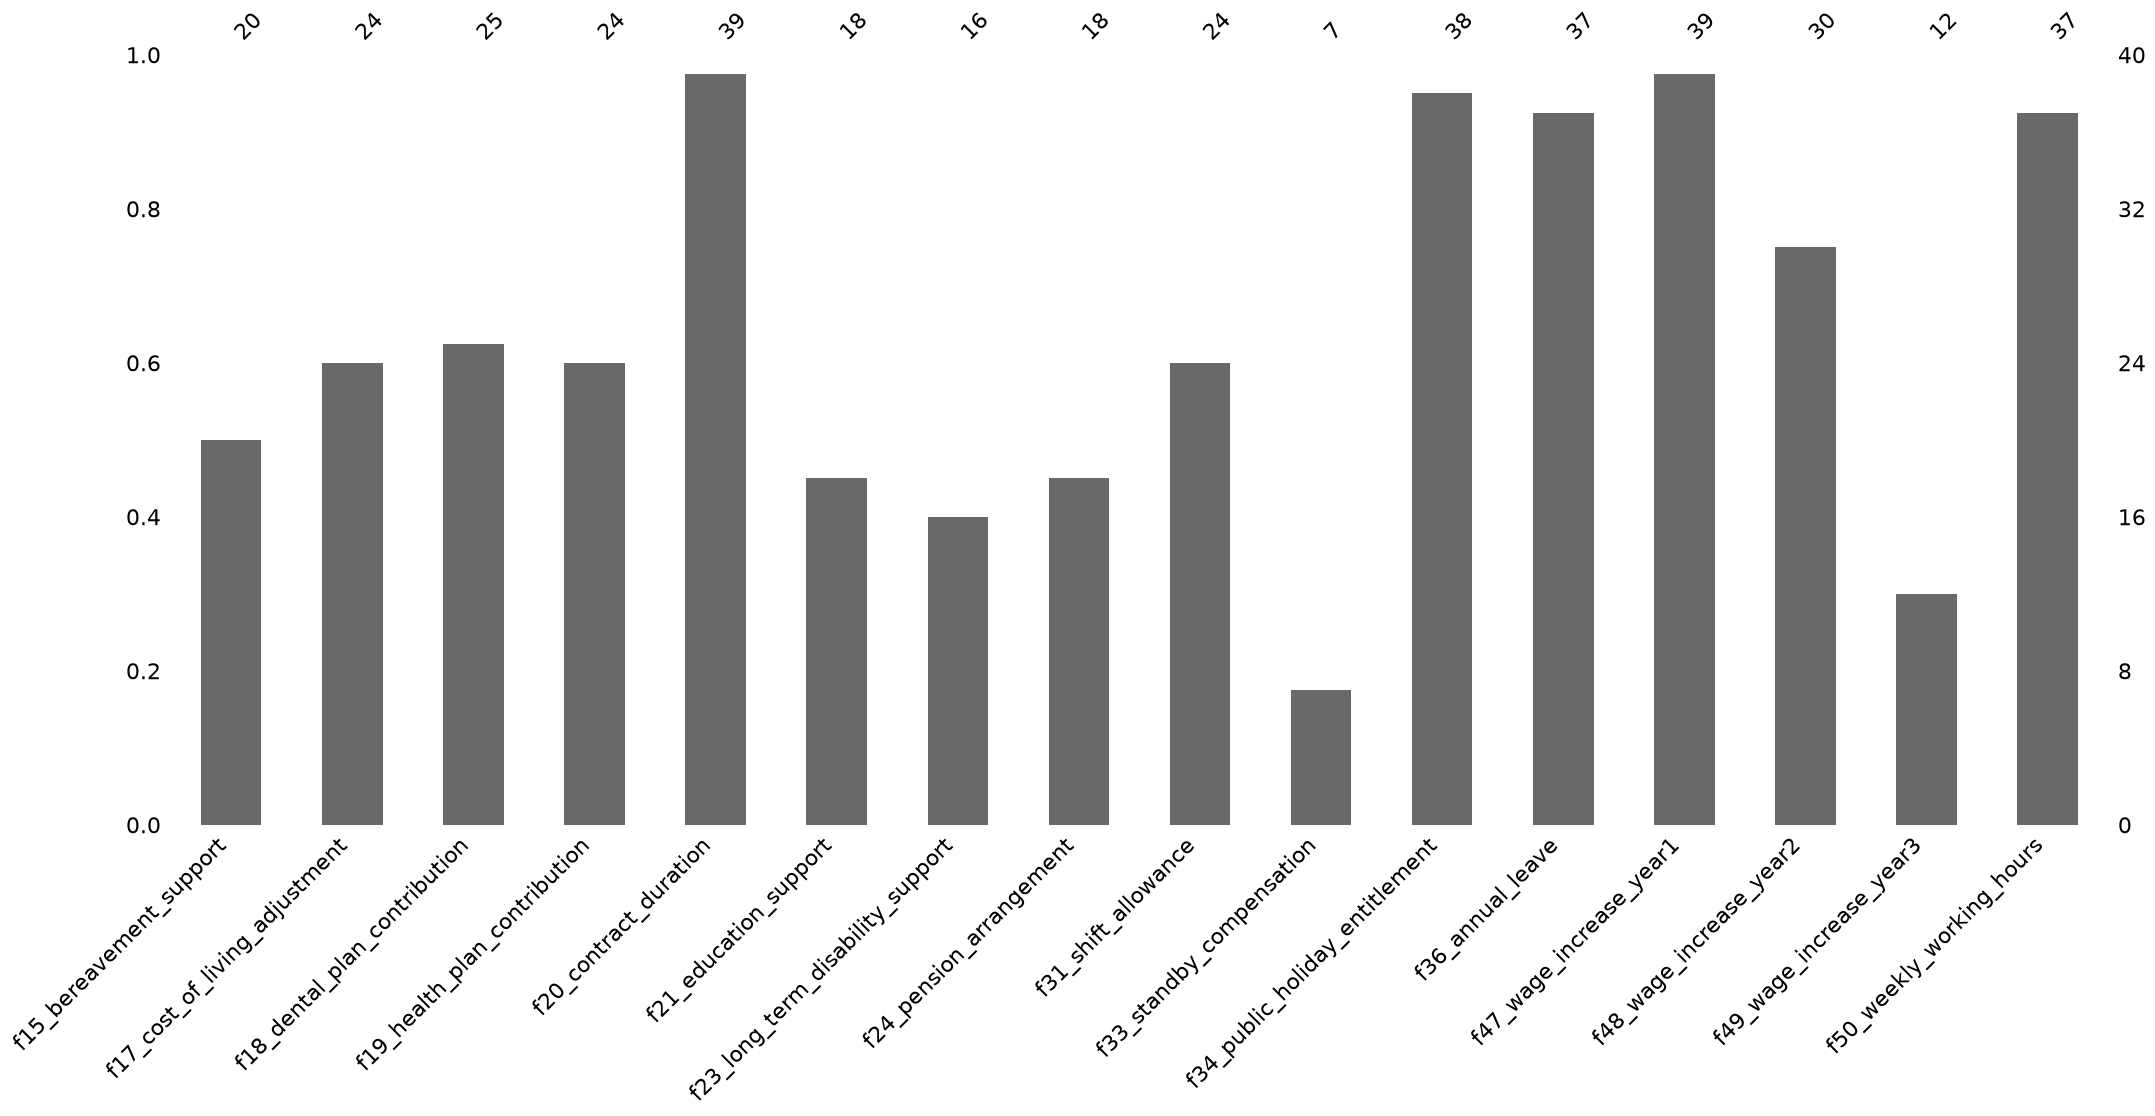

In [24]:
# Inspect or update the intermediate result produced by the preceding step.
# 1.b. bar chart of non-missing values in each column.
msno.bar(X)

<Axes: >

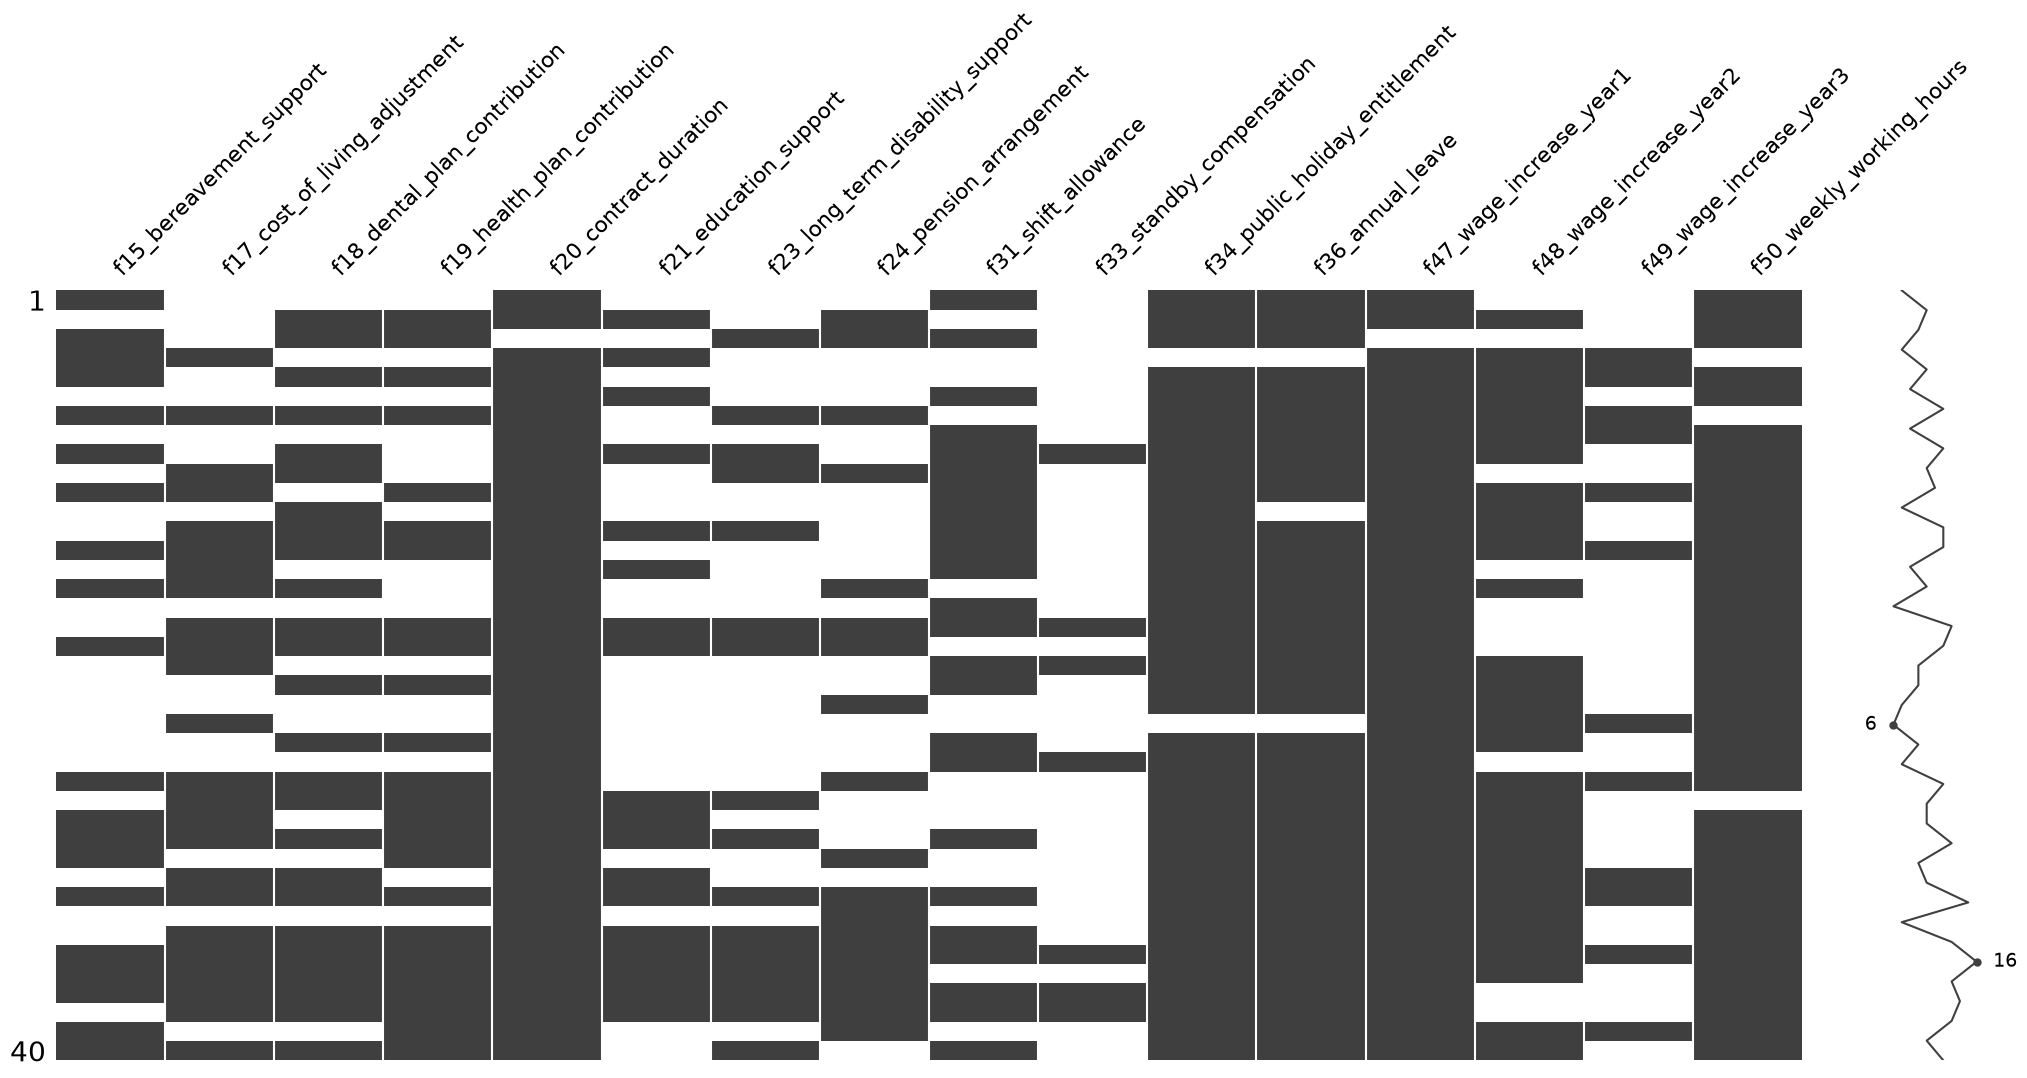

In [25]:
# Inspect or update the intermediate result produced by the preceding step.
# 2. nullity matrix.
msno.matrix(X)

<Axes: >

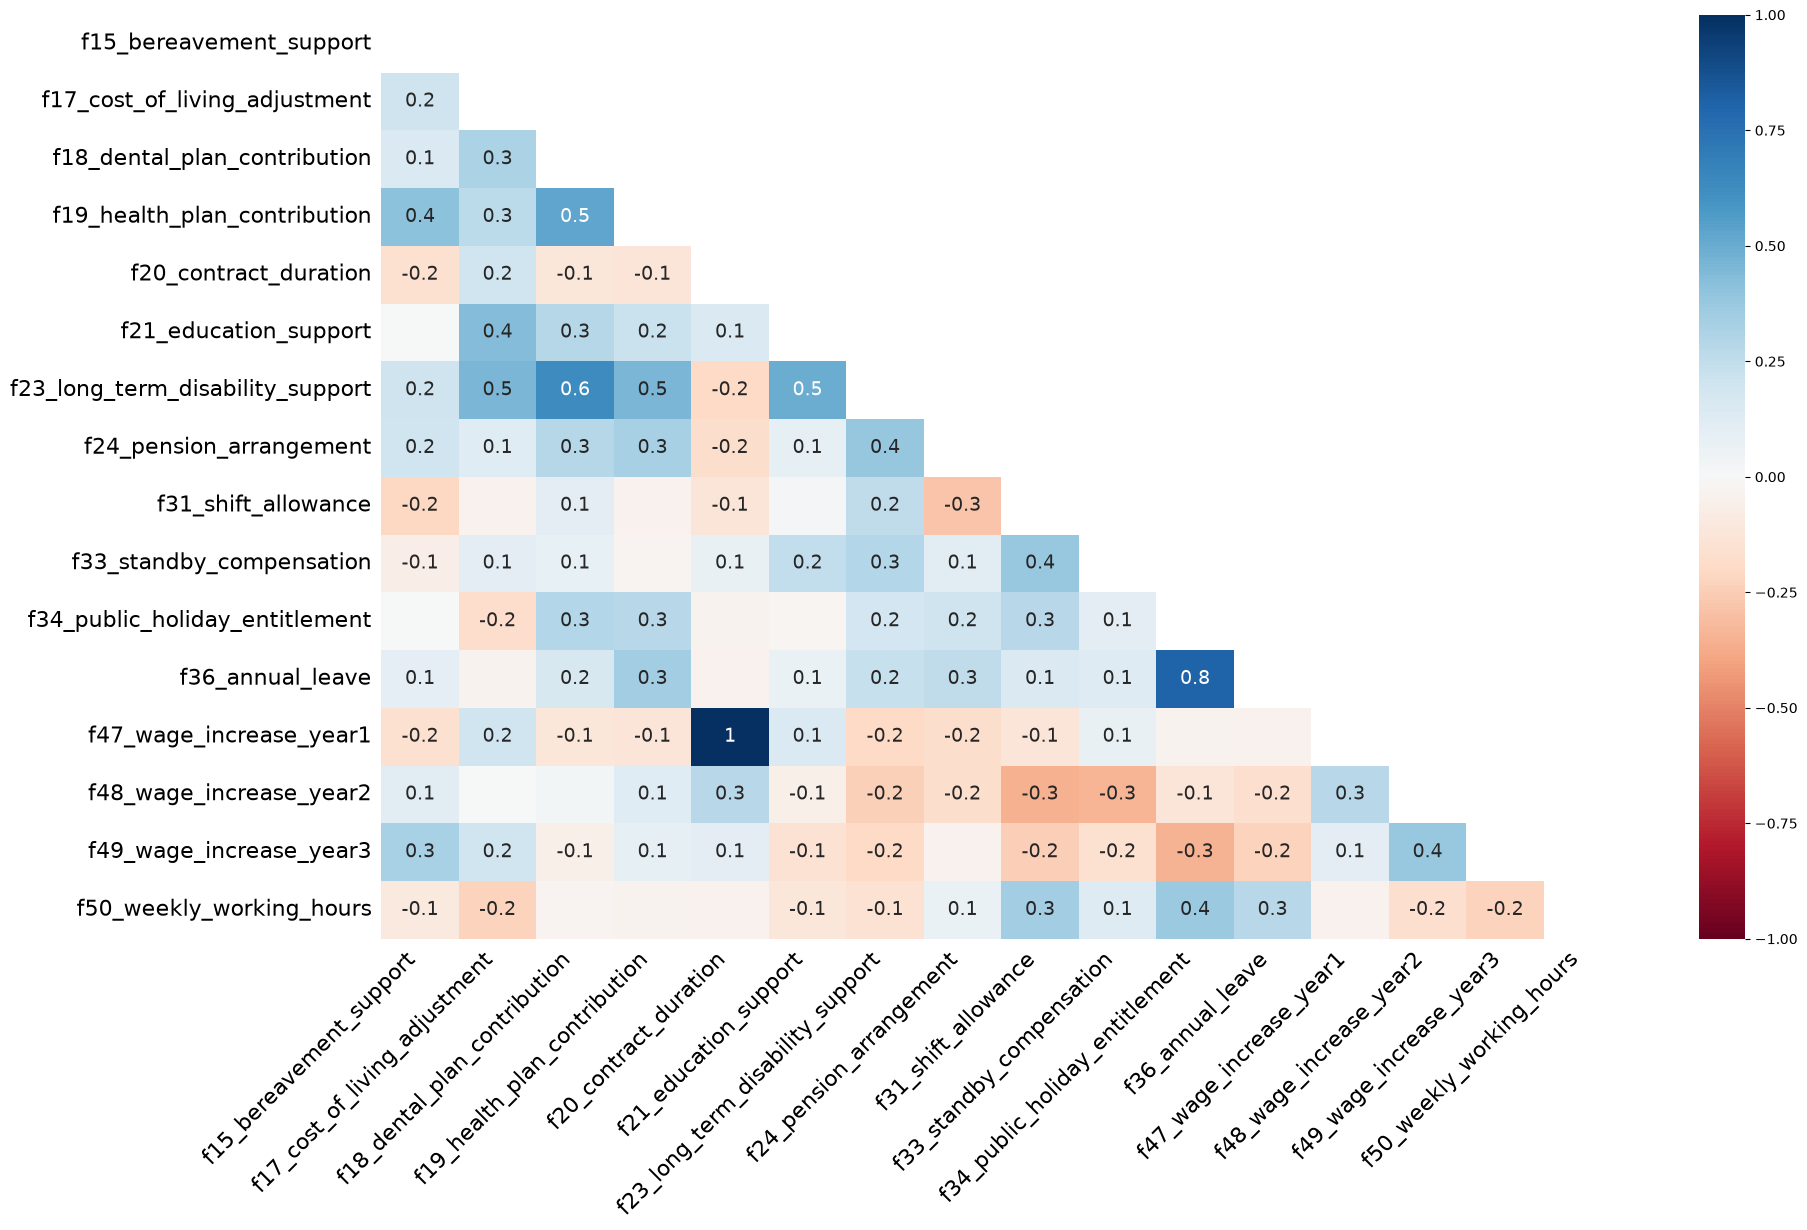

In [26]:
# Inspect or update the intermediate result produced by the preceding step.
# 3. nullity correlation matrix.
msno.heatmap(X)

### Imputation strategies and train/test separation

The notebook compares several treatments for incomplete features and demonstrates how to place imputation within a pipeline. Fit transformations on training data to reduce information leakage into held-out observations.

In [27]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 1. remove columns with too many values missing, over 40%.
mask =  X.columns[(X.isnull().sum() / len(X) * 100) > 40]
print(mask)
X = X.drop(mask, axis=1)
# Update the column names.
obj_cols = X.select_dtypes(exclude=['float64', 'int64', 'int32']).columns
num_cols = X.select_dtypes(include=['float64', 'int64', 'int32']).columns
# Split data into training and testing again and prepare it for algorithm.
# Use the same baseline techniques to fill in the rest.
dt_X[num_cols] = dt_X[num_cols].apply(
      lambda col: col.fillna(0, axis=0)
  )
dt_X[obj_cols] = dt_X[obj_cols].apply(
      lambda col: col.fillna('?', axis=0).astype(str)
  )
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
# Crosss validate and get average performance again.
ad.report_classification_cv(dt_X, y, dt_clf)

Index(['f15_bereavement_support', 'f21_education_support',
       'f23_long_term_disability_support', 'f24_pension_arrangement',
       'f33_standby_compensation', 'f49_wage_increase_year3'],
      dtype='str')
Mean Accuracy is 70.00 +/- 12.75
Mean Precision is 59.13 +/- 24.37
Mean Recall is 67.33 +/- 19.25
Mean F-score is 61.15 +/- 21.30


In [28]:
# Inspect the current dataframe to confirm its structure and values.
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   f17_cost_of_living_adjustment   24 non-null     str    
 1   f18_dental_plan_contribution    25 non-null     str    
 2   f19_health_plan_contribution    24 non-null     str    
 3   f20_contract_duration           39 non-null     float64
 4   f31_shift_allowance             24 non-null     float64
 5   f34_public_holiday_entitlement  38 non-null     float64
 6   f36_annual_leave                37 non-null     str    
 7   f47_wage_increase_year1         39 non-null     float64
 8   f48_wage_increase_year2         30 non-null     float64
 9   f50_weekly_working_hours        37 non-null     float64
dtypes: float64(6), str(4)
memory usage: 3.3 KB


In [29]:
# Inspect the current dataframe to confirm its structure and values.
# Building upon the previous data frames without the id and missing too many values columns.
# Create copy first.
dt_X = X.copy()
# 2.1 use mean for numerical columns if normal distributions and mode for categorical columns.
# Inspect or handle unavailable feature values in this step.
dt_X[num_cols] = dt_X[num_cols].apply(
                    lambda col: col.fillna(col.mean()), axis=0)
# Fill in missing values in categorical columns with mode of each of those columns.
dt_X[obj_cols] = dt_X[obj_cols].apply(
                    lambda col: col.fillna(col.mode()[0]), axis=0)
dt_X.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   f17_cost_of_living_adjustment   40 non-null     str    
 1   f18_dental_plan_contribution    40 non-null     str    
 2   f19_health_plan_contribution    40 non-null     str    
 3   f20_contract_duration           40 non-null     float64
 4   f31_shift_allowance             40 non-null     float64
 5   f34_public_holiday_entitlement  40 non-null     float64
 6   f36_annual_leave                40 non-null     str    
 7   f47_wage_increase_year1         40 non-null     float64
 8   f48_wage_increase_year2         40 non-null     float64
 9   f50_weekly_working_hours        40 non-null     float64
dtypes: float64(6), str(4)
memory usage: 3.3 KB


In [30]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Encode the selected categorical fields for the estimator.
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
# Generate new models based on data filled in missing using mean/mode.
# Crosss validate and get average performance.
ad.report_classification_cv(dt_X, y, dt_clf)

Mean Accuracy is 80.00 +/- 16.96
Mean Precision is 75.89 +/- 26.20
Mean Recall is 76.00 +/- 20.37
Mean F-score is 73.41 +/- 23.72


In [31]:
# Inspect the current dataframe to confirm its structure and values.
# Building upon the previous data frames without the id and missing too many values columns.
# Create copy first.
dt_X = X.copy()
# 2.2. use mean by class for numerical columns and mode by class for categorical columns.
# First we need to add back the class label column.
dt_X['f16_agreement_outcome'] = y
# Fill in missing values in numerical columns with mean by class (we don't have.
# Missing values in numerical columns, but I include the code below for your reference).
dt_X[num_cols] = dt_X.groupby(
    'f16_agreement_outcome')[num_cols].transform(lambda col: col.fillna(col.mean()))
# Fill in missing values in categorical columns with mode by class.
dt_X[obj_cols] = dt_X.groupby('f16_agreement_outcome')[obj_cols].transform(lambda col: col.fillna(col.mode()[0]))
# Exclude the selected values before the next comparison.
dt_X = dt_X.drop('f16_agreement_outcome', axis=1)
dt_X.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   f17_cost_of_living_adjustment   40 non-null     str    
 1   f18_dental_plan_contribution    40 non-null     str    
 2   f19_health_plan_contribution    40 non-null     str    
 3   f20_contract_duration           40 non-null     float64
 4   f31_shift_allowance             40 non-null     float64
 5   f34_public_holiday_entitlement  40 non-null     float64
 6   f36_annual_leave                40 non-null     str    
 7   f47_wage_increase_year1         40 non-null     float64
 8   f48_wage_increase_year2         40 non-null     float64
 9   f50_weekly_working_hours        40 non-null     float64
dtypes: float64(6), str(4)
memory usage: 3.3 KB


In [32]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Encode the selected categorical fields for the estimator.
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
# Generate new models based on data filled in missing using mean/mode by class.
# Crosss validate and get average performance.
ad.report_classification_cv(dt_X, y, dt_clf)

Mean Accuracy is 85.00 +/- 12.25
Mean Precision is 88.14 +/- 10.26
Mean Recall is 86.00 +/- 12.72
Mean F-score is 83.00 +/- 14.16


In [33]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Building upon the previous data frames without the id and missing too many values columns.
# Make a copy first.
dt_X = X.copy()
# 2.3. use scikitlearn KNN imputation (works with numeric values only).
# So we need to encode the obj cols to prepare them for algorithm.
ord_enc = OrdinalEncoder()
dt_X[obj_cols] = ord_enc.fit_transform(dt_X[obj_cols])
from sklearn.impute import KNNImputer
imputer = KNNImputer() # Default n_neighbors=5.
dt_X[list(X.columns)] = imputer.fit_transform(dt_X[list(X.columns)])
# Generate new models based on data filled in missing using knn imputer.
# Crosss validate and get average performance.
ad.report_classification_cv(dt_X, y, dt_clf)

Mean Accuracy is 87.50 +/- 11.18
Mean Precision is 89.81 +/- 8.52
Mean Recall is 87.67 +/- 12.81
Mean F-score is 85.42 +/- 13.31


In [34]:
# Inspect the current dataframe to confirm its structure and values.
# 3.because we have a very small number of rows, we should not remove any;
# However, for bigger datasets where there is no NMAR I have included relevant code below to.
# Exclude the selected values before the next comparison.
# Get indices of rows where the relevant columns, here 'wage-inc-1st' or 'duration', is missing.
indices = dt_X[X['f47_wage_increase_year1'].isnull()|X['f20_contract_duration'].isnull()].index
# Use the indices to drop rows from both regular attributes and class label column.
dt_X_ = dt_X.drop(indices, axis=0)
dt_y_ = y.drop(indices, axis=0)
dt_X_.info()

<class 'pandas.DataFrame'>
Index: 39 entries, 0 to 39
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   f17_cost_of_living_adjustment   39 non-null     float64
 1   f18_dental_plan_contribution    39 non-null     float64
 2   f19_health_plan_contribution    39 non-null     float64
 3   f20_contract_duration           39 non-null     float64
 4   f31_shift_allowance             39 non-null     float64
 5   f34_public_holiday_entitlement  39 non-null     float64
 6   f36_annual_leave                39 non-null     float64
 7   f47_wage_increase_year1         39 non-null     float64
 8   f48_wage_increase_year2         39 non-null     float64
 9   f50_weekly_working_hours        39 non-null     float64
dtypes: float64(10)
memory usage: 3.4 KB


In [35]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 4. add binary variables indicating if observations are missing.
# Will also demonstrate how to use the feature engine classes for imputing.
# Optional comparison: review this configuration against the original baseline.
# Make a copy.
dt_X = X.copy()
from feature_engine.imputation import AddMissingIndicator, CategoricalImputer, MeanMedianImputer
addBinary_imputer = AddMissingIndicator(missing_only=True)
# Fit the imputer and transform the data by adding 3 new columns.
dt_X = addBinary_imputer.fit_transform(dt_X)
# Inspect or handle unavailable feature values in this step.
cat_imputer = CategoricalImputer(variables=list(obj_cols), fill_value='frequent')
num_imputer = MeanMedianImputer(imputation_method='median', variables=list(num_cols))
dt_X = cat_imputer.fit_transform(dt_X)
dt_X = num_imputer.fit_transform(dt_X)
dt_X.info()
# Optional comparison: review this configuration against the original baseline.

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   f17_cost_of_living_adjustment      40 non-null     str    
 1   f18_dental_plan_contribution       40 non-null     str    
 2   f19_health_plan_contribution       40 non-null     str    
 3   f20_contract_duration              40 non-null     float64
 4   f31_shift_allowance                40 non-null     float64
 5   f34_public_holiday_entitlement     40 non-null     float64
 6   f36_annual_leave                   40 non-null     str    
 7   f47_wage_increase_year1            40 non-null     float64
 8   f48_wage_increase_year2            40 non-null     float64
 9   f50_weekly_working_hours           40 non-null     float64
 10  f17_cost_of_living_adjustment_na   40 non-null     int8   
 11  f18_dental_plan_contribution_na    40 non-null     int8   
 12  f19_hea

              precision    recall  f1-score   support

         bad       0.67      1.00      0.80         2
        good       1.00      0.83      0.91         6

    accuracy                           0.88         8
   macro avg       0.83      0.92      0.85         8
weighted avg       0.92      0.88      0.88         8



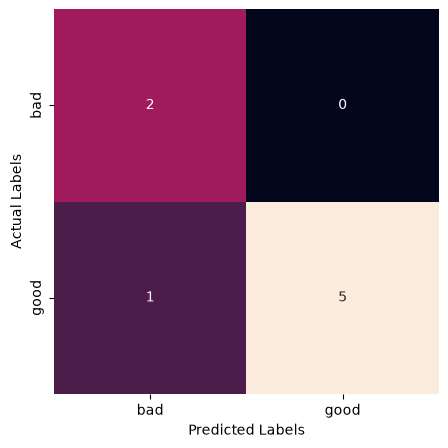

In [36]:
# Create the predefined training and validation partitions without changing split parameters.
# 5. using pipelines to account for future missing values,especially when you.
# Have a big dataset so you can keep a test portion.
# Separate the data.
# Separate the response label from the predictor features.
y = data['f16_agreement_outcome']
X = data[data.columns.difference(['f16_agreement_outcome', 'f04_agreement_record_id'])]
# Drop the columns with more than 40% missing.
mask =  X.columns[(X.isnull().sum() / len(X) * 100) > 40]
X = X.drop(mask, axis=1)
# Get the column names based on dtype.
obj_cols = list(X.select_dtypes(exclude=['float64', 'int64', 'int32']).columns)
num_cols = list(X.select_dtypes(include=['float64', 'int64', 'int32']).columns)

# Fit the estimator using the designated training observations.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)
# Drop rows where there are missing values in cols that have less than 5% missing.
from feature_engine.imputation import DropMissingData
drop_missing_imp =  DropMissingData(missing_only=True, threshold=0.95)
# Adjust the number of rows in the regular attributes and the label column.
X_train = drop_missing_imp.fit_transform(X_train)
y_train = y_train[X_train.index]
# Add missing indicator.
add_ind_imp = AddMissingIndicator(missing_only=True)
# Inspect or handle unavailable feature values in this step.
from feature_engine.imputation import MeanMedianImputer
# We do not have numeric cols with missing, but the imputer is shown below.
num_imp = MeanMedianImputer(imputation_method='mean', variables=list(num_cols))
cat_imp = CategoricalImputer(variables=list(obj_cols), fill_value='frequent')
# Encoder for categorical variables; ensure to deal with unknown values on the test portion.
ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
# The classifier.
dt_clf = DecisionTreeClassifier(random_state=43)
# Create the pipeline.
from sklearn.pipeline import Pipeline
pipeline = Pipeline([
    ('add_ind_imp', add_ind_imp),
    ('num_imp', num_imp),
    ('cat_imp', cat_imp),
    ('ord_enc', ord_enc)
])
# Add classifier to the pipeline.
pipeline.steps.append(['clf', dt_clf])
# Fit the estimator using the designated training observations.
pipeline.fit(X_train, y_train)
# Generate predictions from the fitted estimator.
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))
ad.display_confusion_matrix(y_test, y_pred)

## 4. Discretize numerical predictors

Using botanical measurements, compare equal-frequency, equal-width and model-guided bins. Record both transformed feature structure and model performance when examining discretization.

In [37]:
# Load the project dataset from its local data directory and inspect its schema.
iris = pd.read_csv('data/iris_species_measurements.csv', sep=',')
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   f29_sepal_length_cm  150 non-null    float64
 1   f30_sepal_width_cm   150 non-null    float64
 2   f25_petal_length_cm  150 non-null    float64
 3   f26_petal_width_cm   150 non-null    float64
 4   f32_flower_species   150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [38]:
# Inspect the current dataframe to confirm its structure and values.
iris.head()

,f29_sepal_length_cm,f30_sepal_width_cm,f25_petal_length_cm,f26_petal_width_cm,f32_flower_species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [39]:
# Create the predefined training and validation partitions without changing split parameters.
# Separate regular attributes from the label column.
X_iris = iris[iris.columns.difference(['f32_flower_species'])]
y_iris = iris['f32_flower_species']
# Fit the estimator using the designated training observations.
X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.2, random_state=43)

In [40]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Baseline performance - with no preparation (apart from necessary one for.
# Classification algorithm to run) and no hyperparameter tuning.
dt_clf = DecisionTreeClassifier(random_state=43)
ad.report_classification_cv(X_train, y_train, dt_clf)

Mean Accuracy is 92.50 +/- 4.86
Mean Precision is 93.01 +/- 4.71
Mean Recall is 92.78 +/- 4.66
Mean F-score is 92.77 +/- 4.74


In [41]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 1.a. unsupervised equal fequency discretisation.
# Fit the estimator using the designated training observations.
ef_train_data = X_train.copy()
from feature_engine.discretisation import EqualFrequencyDiscretiser
# Create a equal frequency binner with 10 bins.
equal_freq_binner = EqualFrequencyDiscretiser(q=10,
          variables=list(X_train.columns),
          return_boundaries=True)
# Fit the estimator using the designated training observations.
ef_train_data = equal_freq_binner.fit_transform(ef_train_data)
ef_train_data.head()

,f25_petal_length_cm,f26_petal_width_cm,f29_sepal_length_cm,f30_sepal_width_cm
96,"(4.0, 4.45]","(1.2, 1.4]","(5.6, 5.8]","(2.87, 3.0]"
19,"(1.4, 1.5]","(0.28, 0.57]","(4.9, 5.1]","(3.7, inf]"
93,"(1.9, 4.0]","(0.57, 1.2]","(4.9, 5.1]","(-inf, 2.5]"
98,"(1.9, 4.0]","(0.57, 1.2]","(4.9, 5.1]","(-inf, 2.5]"
108,"(5.71, inf]","(1.5, 1.8]","(6.62, 6.9]","(-inf, 2.5]"


In [42]:
# Inspect or update the intermediate result produced by the preceding step.
# Output the bin boundaries for each variable.
equal_freq_binner.binner_dict_

{'f25_petal_length_cm': [-inf,
  np.float64(1.4),
  np.float64(1.5),
  np.float64(1.9),
  np.float64(4.0),
  np.float64(4.45),
  np.float64(4.7),
  np.float64(5.030000000000002),
  np.float64(5.4),
  np.float64(5.710000000000001),
  inf],
 'f26_petal_width_cm': [-inf,
  np.float64(0.2),
  np.float64(0.2800000000000001),
  np.float64(0.570000000000001),
  np.float64(1.2),
  np.float64(1.4),
  np.float64(1.5),
  np.float64(1.8),
  np.float64(1.9),
  np.float64(2.2),
  inf],
 'f29_sepal_length_cm': [-inf,
  np.float64(4.9),
  np.float64(5.1),
  np.float64(5.4),
  np.float64(5.6),
  np.float64(5.8),
  np.float64(6.1400000000000015),
  np.float64(6.4),
  np.float64(6.62),
  np.float64(6.9),
  inf],
 'f30_sepal_width_cm': [-inf,
  np.float64(2.5),
  np.float64(2.7),
  np.float64(2.870000000000001),
  np.float64(3.0),
  np.float64(3.1),
  np.float64(3.2),
  np.float64(3.4),
  np.float64(3.7),
  inf]}

In [43]:
# Inspect or update the intermediate result produced by the preceding step.
# Output the number of values in each bin of petallength discretised.
ef_train_data.f25_petal_length_cm.value_counts()

f25_petal_length_cm
(-inf, 1.4]    16
(4.45, 4.7]    15
(1.9, 4.0]     13
(5.03, 5.4]    13
(5.71, inf]    12
(5.4, 5.71]    11
(1.5, 1.9]     11
(4.0, 4.45]    10
(1.4, 1.5]     10
(4.7, 5.03]     9
Name: count, dtype: int64

In [44]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Convert the categorical columns to numeric ones.
ef_train_data[X_train.columns] = OrdinalEncoder().fit_transform(ef_train_data[X_train.columns])
# Compare predictions across the configured validation folds.
ad.report_classification_cv(ef_train_data, y_train, dt_clf)

Mean Accuracy is 95.00 +/- 3.12
Mean Precision is 95.59 +/- 2.88
Mean Recall is 95.28 +/- 2.96
Mean F-score is 95.18 +/- 3.05


In [45]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 1.b. unsupervised equal width discretisation.
# Fit the estimator using the designated training observations.
ew_train_data = X_train.copy()
from feature_engine.discretisation import EqualWidthDiscretiser
# Create a equal frequency binner with 10 bins.
equal_width_binner = EqualWidthDiscretiser(bins=10,
          variables=list(X_train.columns),
          return_boundaries=True)
# Fit the estimator using the designated training observations.
ew_train_data = equal_width_binner.fit_transform(ew_train_data)
# Output the number of values in each bin of petallength discretised.
ew_train_data.f25_petal_length_cm.value_counts()

f25_petal_length_cm
(-inf, 1.57]    26
(4.42, 4.99]    21
(4.99, 5.56]    19
(3.85, 4.42]    17
(5.56, 6.13]    17
(1.57, 2.14]    11
(3.28, 3.85]     5
(6.13, inf]      3
(2.71, 3.28]     1
Name: count, dtype: int64

In [46]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Convert the categorical columns to numeric ones.
ew_train_data[X_train.columns] = OrdinalEncoder().fit_transform(ew_train_data[X_train.columns])
# Compare predictions across the configured validation folds.
ad.report_classification_cv(ew_train_data, y_train, dt_clf)

Mean Accuracy is 95.00 +/- 4.08
Mean Precision is 95.43 +/- 4.19
Mean Recall is 95.19 +/- 3.75
Mean F-score is 95.12 +/- 4.01


In [47]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 1.c. using the sklearn KBinsDiscretizer with kmeans strategy.
k_train_data = X_train.copy()
# Let's use the default of 10 bins and ordinal encoding.
from sklearn.preprocessing import KBinsDiscretizer
k_binner = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='kmeans', random_state=43)
k_train_data[X_train.columns] = k_binner.fit_transform(k_train_data)
print(k_binner.bin_edges_)
# Crossvalidate on the binned attributes and get performance.
ad.report_classification_cv(k_train_data, y_train, dt_clf)

[array([1.        , 1.27386364, 1.55681818, 2.34545455, 3.27      ,
        3.84352941, 4.4092437 , 4.94097744, 5.50526316, 6.13333333,
        6.7       ])
 array([0.1       , 0.308867  , 0.50714286, 0.82142857, 1.1547619 ,
        1.36568627, 1.54901961, 1.75087719, 2.00296053, 2.24602273,
        2.5       ])
 array([4.3       , 4.74325397, 5.05941558, 5.35454545, 5.74914773,
        6.13658088, 6.47470588, 6.75285714, 7.05952381, 7.5       ,
        7.9       ])
 array([2.        , 2.235     , 2.425     , 2.64147059, 2.87917329,
        3.11740859, 3.3289916 , 3.53428571, 3.7325    , 3.9625    ,
        4.2       ])                                               ]
Mean Accuracy is 95.00 +/- 4.08
Mean Precision is 95.43 +/- 4.19
Mean Recall is 95.19 +/- 3.75
Mean F-score is 95.12 +/- 4.01


### Search over binning configurations

A parameter search can compare candidate bin counts and encoding choices. Interpret the selected configuration using the same validation setup as the baseline.

In [48]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
pipeline = Pipeline([
    ('binner', KBinsDiscretizer( random_state=43)),
    ('classifier', dt_clf)
])
# Define the list of parameter values we want to check, but because we have.
# Multiple steps in the pipeline we need to specify the name of the step to.
# Which these values apply by adding the prefix nameOfStep__, e.g., binner_ for.
# Binning, or classifier__ for classifier, but here we focus on binning.
params = {
    'binner__n_bins': range(3, 10),
    'binner__strategy': ['uniform', 'quantile', 'kmeans']
}
grid = GridSearchCV(pipeline, param_grid=params, verbose=3)
grid.fit(X_train, y_train)
grid.best_params_, grid.best_score_

Fitting 5 folds for each of 21 candidates, totalling 105 fits
[CV 1/5] END binner__n_bins=3, binner__strategy=uniform;, score=0.917 total time=   0.0s
[CV 2/5] END binner__n_bins=3, binner__strategy=uniform;, score=0.917 total time=   0.0s
[CV 3/5] END binner__n_bins=3, binner__strategy=uniform;, score=0.917 total time=   0.0s
[CV 4/5] END binner__n_bins=3, binner__strategy=uniform;, score=0.958 total time=   0.0s
[CV 5/5] END binner__n_bins=3, binner__strategy=uniform;, score=0.958 total time=   0.0s
[CV 1/5] END binner__n_bins=3, binner__strategy=quantile;, score=0.833 total time=   0.0s
[CV 2/5] END binner__n_bins=3, binner__strategy=quantile;, score=0.917 total time=   0.0s
[CV 3/5] END binner__n_bins=3, binner__strategy=quantile;, score=0.958 total time=   0.0s
[CV 4/5] END binner__n_bins=3, binner__strategy=quantile;, score=0.917 total time=   0.0s
[CV 5/5] END binner__n_bins=3, binner__strategy=quantile;, score=0.958 total time=   0.0s
[CV 1/5] END binner__n_bins=3, binner__stra

({'binner__n_bins': 3, 'binner__strategy': 'kmeans'}, np.float64(0.95))

In [49]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2. a. supervised binning - using the predicted values as the new values.
sup_bin_train_data = X_train.copy()
from feature_engine.discretisation import DecisionTreeDiscretiser
dt_binner = DecisionTreeDiscretiser(cv=5, scoring='accuracy', regression=False, random_state=43)
sup_bin_train_data[X_train.columns] = dt_binner.fit_transform(sup_bin_train_data, y_train)
sup_bin_train_data.head()

,f25_petal_length_cm,f26_petal_width_cm,f29_sepal_length_cm,f30_sepal_width_cm
96,0.974359,1.0,0.818182,0.455556
19,0.000000,0.0,0.200000,0.033333
93,0.974359,1.0,0.200000,0.455556
98,0.974359,1.0,0.200000,0.455556
108,0.090909,0.1,0.342105,0.455556


In [50]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2. b. supervised binning - using the bin numbers as the new values.
sup_bin_train_data = X_train.copy()
from feature_engine.discretisation import DecisionTreeDiscretiser
dt_binner = DecisionTreeDiscretiser(bin_output='bin_number', cv=5, scoring='accuracy', regression=False, random_state=43)
sup_bin_train_data[X_train.columns] = dt_binner.fit_transform(sup_bin_train_data, y_train)
sup_bin_train_data.head()

,f25_petal_length_cm,f26_petal_width_cm,f29_sepal_length_cm,f30_sepal_width_cm
96,1,1,5,0
19,0,0,2,1
93,1,1,2,0
98,1,1,2,0
108,2,3,8,0


In [51]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2. c. supervised binning - using the bin boundaries as the new values.
# Additionally, we can specify the configuration of the classifier.
sup_bin_train_data = X_train.copy()
from feature_engine.discretisation import DecisionTreeDiscretiser
dt_binner = DecisionTreeDiscretiser(bin_output='boundaries', cv=5, precision=2,
                scoring='accuracy', regression=False, random_state=43,
                param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]},)
sup_bin_train_data[X_train.columns] = dt_binner.fit_transform(sup_bin_train_data, y_train)
sup_bin_train_data.head()

,f25_petal_length_cm,f26_petal_width_cm,f29_sepal_length_cm,f30_sepal_width_cm
96,"(2.45, 4.45]","(0.8, 1.45]","(5.45, 5.75]","(-inf, 3.35]"
19,"(-inf, 2.45]","(-inf, 0.8]","(4.95, 5.45]","(3.35, inf]"
93,"(2.45, 4.45]","(0.8, 1.45]","(4.95, 5.45]","(-inf, 3.35]"
98,"(2.45, 4.45]","(0.8, 1.45]","(4.95, 5.45]","(-inf, 3.35]"
108,"(5.05, inf]","(1.75, 1.85]","(6.15, 7.05]","(-inf, 3.35]"


### Follow-up comparisons

Compare selected discretization strategies and model settings against the unchanged baseline; avoid interpreting fold-to-fold fluctuations as meaningful improvement.

## 5. Identify unusual observations

Explore synthetic observations through summary statistics and multivariate plots. Distinguish extreme individual measurements from observations isolated in joint feature space.

In [52]:
# Load the project dataset from its local data directory and inspect its schema.
outlier_data = pd.read_csv('data/synthetic_outlier_samples.csv')
outlier_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   f13_measured_axis_a   50 non-null     float64
 1   f14_measured_axis_b   50 non-null     float64
 2   f27_random_reference  50 non-null     float64
 3   f22_cluster_group     50 non-null     int64  
dtypes: float64(3), int64(1)
memory usage: 1.7 KB


### Initial exploration

Inspect distributions and class frequencies before applying outlier rules.

In [53]:
# Inspect or update the intermediate result produced by the preceding step.
outlier_data.f22_cluster_group.value_counts()

f22_cluster_group
2    13
3    10
6     7
1     5
5     5
4     5
7     5
Name: count, dtype: int64

In [54]:
# Inspect the current dataframe to confirm its structure and values.
outlier_data[['f13_measured_axis_a', 'f14_measured_axis_b', 'f27_random_reference']].describe()

,f13_measured_axis_a,f14_measured_axis_b,f27_random_reference
count,50.000000,50.000000,50.000000
mean,-1.389884,-0.642577,-0.098170
std,5.487209,5.390374,1.056734
min,-9.194915,-9.528415,-2.536272
25%,-6.222359,-4.152599,-0.748327
50%,-2.209035,-1.066278,-0.167455
75%,3.402679,2.378234,0.490010
max,9.834681,9.345589,2.141908


array([[<Axes: title={'center': 'f13_measured_axis_a'}>,
        <Axes: title={'center': 'f14_measured_axis_b'}>],
       [<Axes: title={'center': 'f27_random_reference'}>, <Axes: >]],
      dtype=object)

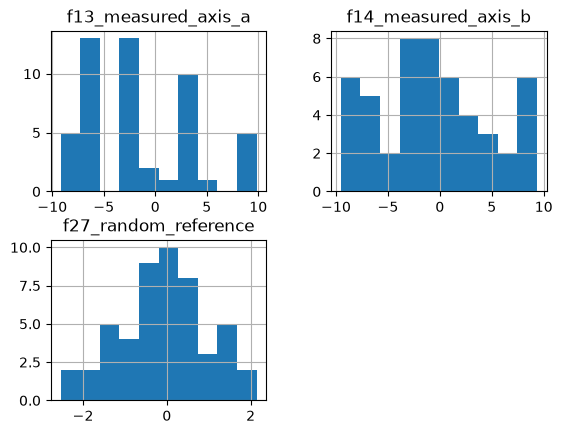

In [55]:
# Inspect or update the intermediate result produced by the preceding step.
outlier_data[['f13_measured_axis_a', 'f14_measured_axis_b', 'f27_random_reference']].hist()

In [56]:
# Inspect relationships in the selected features using a three-dimensional plot.
px.scatter_3d(outlier_data, x='f13_measured_axis_a', y='f14_measured_axis_b',
                    z='f27_random_reference')

Mean Accuracy is 87.50 +/- 7.91
Mean Precision is 82.22 +/- 11.99
Mean Recall is 86.67 +/- 8.50
Mean F-score is 82.67 +/- 11.19
              precision    recall  f1-score   support

           1       0.67      1.00      0.80         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         1
           5       1.00      1.00      1.00         2
           6       1.00      0.50      0.67         2
           7       0.00      0.00      0.00         1

    accuracy                           0.80        10
   macro avg       0.72      0.75      0.71        10
weighted avg       0.77      0.80      0.75        10



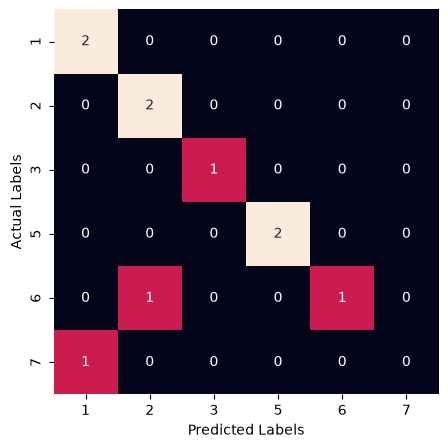

In [57]:
# Create the predefined training and validation partitions without changing split parameters.
# Separate regular attributes from the label attribute.
X_outlier = outlier_data[outlier_data.columns.difference(['f22_cluster_group'])]
y_outlier = outlier_data['f22_cluster_group']
X_train, X_test, y_train, y_test = train_test_split(
    X_outlier, y_outlier, test_size=0.2, random_state=43
)
# Get the baseline model and crossvalidate on the train portion.
ad.report_classification_cv(X_train, y_train, dt_clf)
# Apply the model to the test portion.
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))
ad.display_confusion_matrix(y_test, y_pred)

### Univariate capping and removal

Compare Gaussian, interquartile-range and median-absolute-deviation thresholds. Capping retains rows while trimming removes them; either choice may affect downstream estimates.

In [58]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from feature_engine.outliers import Winsorizer
# 1.a. replace outliers using the gaussian method (can do one or both tails).
capper = Winsorizer(
    capping_method='gaussian', tail='both')
# Fit the estimator using the designated training observations.
capper.fit(X_train)
# Output the maximum caps allowed.
capper.right_tail_caps_, capper.left_tail_caps_

({'f13_measured_axis_a': 13.183022345016251,
  'f14_measured_axis_b': 14.075428911405833,
  'f27_random_reference': 2.7259474035424724},
 {'f13_measured_axis_a': -17.205200335463832,
  'f14_measured_axis_b': -15.982942720417217,
  'f27_random_reference': -3.049112246890567})

Mean Accuracy is 87.50 +/- 7.91
Mean Precision is 82.22 +/- 11.99
Mean Recall is 86.67 +/- 8.50
Mean F-score is 82.67 +/- 11.19
              precision    recall  f1-score   support

           1       0.67      1.00      0.80         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         1
           5       1.00      1.00      1.00         2
           6       1.00      0.50      0.67         2
           7       0.00      0.00      0.00         1

    accuracy                           0.80        10
   macro avg       0.72      0.75      0.71        10
weighted avg       0.77      0.80      0.75        10



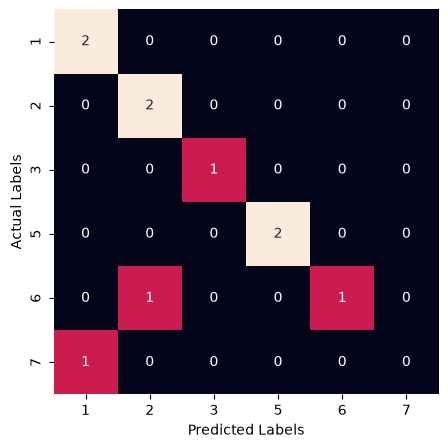

In [59]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Fit the estimator using the designated training observations.
X_train_gauss = capper.transform(X_train)
ad.report_classification_cv(X_train_gauss, y_train, dt_clf)
# To test on unseen data, transform the test portion.
X_test_gauss = capper.transform(X_test)
y_pred = dt_clf.predict(X_test_gauss)
print(classification_report(y_test, y_pred))
ad.display_confusion_matrix(y_test, y_pred)

In [60]:
# Continue the analysis using the original transformation and model parameters.
# 1.b. replace outliers using the IQR method at both tails.
capper = Winsorizer(
    capping_method='iqr', tail='both')
# Fit the estimator using the designated training observations.
capper.fit(X_train)
# Output the maximum caps allowed.
capper.right_tail_caps_, capper.left_tail_caps_

({'f13_measured_axis_a': 13.551459024605846,
  'f14_measured_axis_b': 11.029563469951768,
  'f27_random_reference': 2.3468825468994057},
 {'f13_measured_axis_a': -18.190059363563506,
  'f14_measured_axis_b': -12.90814553877106,
  'f27_random_reference': -2.7183794341396434})

In [61]:
# Continue the analysis using the original transformation and model parameters.
# 1.c. replace outliers using the MAD method at both tails.
capper = Winsorizer(
    capping_method='mad', tail='both')
# Fit the estimator using the designated training observations.
capper.fit(X_train)
# Output the maximum caps allowed.
capper.right_tail_caps_, capper.left_tail_caps_

({'f13_measured_axis_a': 15.839524050979426,
  'f14_measured_axis_b': 15.066119853827294,
  'f27_random_reference': 2.8604777335287577},
 {'f13_measured_axis_a': -21.053647889979427,
  'f14_measured_axis_b': -17.531464536827293,
  'f27_random_reference': -3.195388425528758})

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         1
           5       1.00      1.00      1.00         2
           6       1.00      0.50      0.67         2
           7       1.00      1.00      1.00         1

    accuracy                           0.90        10
   macro avg       0.94      0.92      0.91        10
weighted avg       0.93      0.90      0.89        10



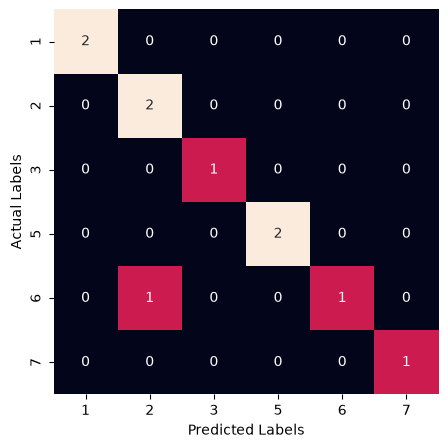

In [62]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2.a. remove outliers using the gaussian method at both tails.
# The resulting caps are the same as for the winsor, the differnce is.
# That now rows where these outliers occur are removed, so, in order to get.
# Performance, we need to adjust y portions too.
# One of the options is to use the feature_engine.Pipeline.
from feature_engine.pipeline import Pipeline
from feature_engine.outliers import OutlierTrimmer
trimmer = OutlierTrimmer(
    capping_method='iqr', tail='both')
# Build the pipeline.
pipeline = Pipeline([
    ('trimmer', trimmer),
    ('clf', dt_clf)
])

# Fit the estimator using the designated training observations.
pipeline.fit(X_train, y_train)
# To test on unseen data, transform the test portion.
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))
ad.display_confusion_matrix(y_test, y_pred)

### Local Outlier Factor

Use neighborhood density to flag observations whose local structure differs from nearby records. Review the selected points before removing them.

In [63]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.neighbors import LocalOutlierFactor
X_outlier_lof = X_train.copy()
# Leave all hyperparameters to default values.
lof = LocalOutlierFactor() # N_neighbors=20 by default.
# Inspect unusual observations using the selected detection rule.
outlier_scores = lof.fit_predict(X_outlier_lof)
# Inspect unusual observations using the selected detection rule.
X_outlier_lof['outlier_score'] = outlier_scores
print(X_outlier_lof.head())
# Can select only the outlier rows - those that have a score of -1.
outlier_rows = X_outlier_lof[X_outlier_lof['outlier_score'] == -1]
print('len=', len(outlier_rows))
outlier_rows

    f13_measured_axis_a  f14_measured_axis_b  f27_random_reference  \
18            -6.095511            -9.528415              0.002998   
29            -6.075241            -8.995997             -2.536272   
3             -2.729632            -1.008135              1.026901   
37            -6.031073            -4.898363              0.065306   
5              9.598148             9.345589             -0.951391   

    outlier_score  
18              1  
29              1  
3               1  
37              1  
5              -1  
len= 3


,f13_measured_axis_a,f14_measured_axis_b,f27_random_reference,outlier_score
5,9.598148,9.345589,-0.951391,-1
7,9.812447,8.853770,-1.378401,-1
16,9.371052,8.359772,-0.906486,-1


In [64]:
# Inspect the current dataframe to confirm its structure and values.
X_outlier_lof = X_train.copy()
# Change k to 7 and contamination to.
lof = LocalOutlierFactor(n_neighbors=7, contamination=0.05)
# Inspect unusual observations using the selected detection rule.
outlier_scores = lof.fit_predict(X_outlier_lof)
# Inspect unusual observations using the selected detection rule.
X_outlier_lof['outlier_score'] = outlier_scores
print(X_outlier_lof.head())
# Can select only the outlier rows - those that have a score of -1.
outlier_rows = X_outlier_lof[X_outlier_lof['outlier_score'] == -1]
print('len=', len(outlier_rows))
outlier_rows

    f13_measured_axis_a  f14_measured_axis_b  f27_random_reference  \
18            -6.095511            -9.528415              0.002998   
29            -6.075241            -8.995997             -2.536272   
3             -2.729632            -1.008135              1.026901   
37            -6.031073            -4.898363              0.065306   
5              9.598148             9.345589             -0.951391   

    outlier_score  
18              1  
29              1  
3               1  
37              1  
5              -1  
len= 2


,f13_measured_axis_a,f14_measured_axis_b,f27_random_reference,outlier_score
5,9.598148,9.345589,-0.951391,-1
7,9.812447,8.853770,-1.378401,-1


Mean Accuracy is 84.64 +/- 12.20
Mean Precision is 77.05 +/- 18.52
Mean Recall is 81.33 +/- 16.81
Mean F-score is 77.40 +/- 18.23
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         1
           5       1.00      1.00      1.00         2
           6       1.00      0.50      0.67         2
           7       1.00      1.00      1.00         1

    accuracy                           0.90        10
   macro avg       0.94      0.92      0.91        10
weighted avg       0.93      0.90      0.89        10



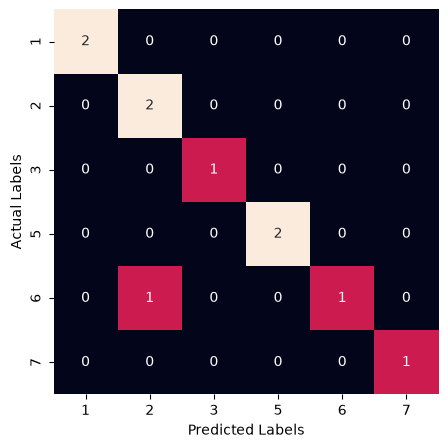

In [65]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Inspect unusual observations using the selected detection rule.
X_outlier_lof = X_outlier_lof.drop(outlier_rows.index, axis=0)
# Fit the estimator using the designated training observations.
y_outlier_lof = y_train.drop(outlier_rows.index, axis=0)
# Remove the specified fields or rows for this experimental variant.
X_outlier_lof = X_outlier_lof.drop('outlier_score', axis=1)
# Compare predictions across the configured validation folds.
ad.report_classification_cv(X_outlier_lof, y_outlier_lof, dt_clf)
# Inspect unusual observations using the selected detection rule.
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))
ad.display_confusion_matrix(y_test, y_pred)

### Isolation Forest

This optional section uses tree-based isolation to highlight unusual observations. Its anomaly score should be interpreted within the chosen contamination setting.

In [ ]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.ensemble import IsolationForest
X_outlier_if = X_train.copy()
is_for = IsolationForest(contamination='auto', random_state=43)
# 1. detect the outlier rows.
outlier_scores = is_for.fit_predict(X_outlier_if)
# Inspect unusual observations using the selected detection rule.
X_outlier_if['outlier_score'] = outlier_scores
print(X_outlier_if.head())
# Can select only the outlier rows - those that have a score of -1.
outlier_rows = X_outlier_if[X_outlier_if['outlier_score'] == -1]
print('len=', len(outlier_rows))
outlier_rows

## 6. Put preparation inside validation

Use a risk-profile dataset to illustrate preprocessing inside classification pipelines. Keep train/test separation explicit and avoid fitting preparation steps on the complete dataset before validation.

In [ ]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold

# Function to do split validation for an entire pipeline.
def evaluate_pipeline_holdout(clf, preparations, X_train, y_train, X_test, y_test):
  # Add preparation steps and classification step to the pipeline.
  pipeline = Pipeline(steps=[('preprocessing', preparations), ('classification', clf)])
  pipeline.fit(X_train, y_train)
  predictions = pipeline.predict(X_test)
  return (accuracy_score(y_test, predictions),
          precision_score(y_test, predictions, average='macro'),
          recall_score(y_test, predictions, average='macro'),
          f1_score(y_test, predictions, average='macro'))

# Function to do cross validation for an entire pipeline.
def evaluate_pipeline_cv(clf, preparations, X, y, folds=5):
  skf = StratifiedKFold(n_splits=folds)
  accuracies = []
  precisions = []
  recalls = []
  f1s = []
  for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    scores = evaluate_pipeline_holdout(clf, preparations, X_train, y_train, X_test, y_test)
    accuracies.append(scores[0])
    precisions.append(scores[1])
    recalls.append(scores[2])
    f1s.append(scores[3])
  print("Overal accuracy: %0.2f, std: %0.2f" % (np.array(accuracies).mean(),
                                                np.array(accuracies).std()))
  print("Overal precision: %0.2f, std: %0.2f" % (np.array(precisions).mean(),
                                                np.array(precisions).std()))
  print("Overal recall: %0.2f, std: %0.2f" % (np.array(recalls).mean(),
                                                np.array(recalls).std()))
  print("Overal F1-score: %0.2f, std: %0.2f" % (np.array(f1s).mean(),
                                                np.array(f1s).std()))

In [ ]:
# Load the project dataset from its local data directory and inspect its schema.
risk = pd.read_csv('data/risk_profile_records.csv', sep=';')
risk.info()

In [ ]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# We will use an SVM classifier.
from sklearn.svm import SVC
clf = SVC(random_state=1)

# Separate the reg.attr. from the label attr.
risk_X = risk[risk.columns.difference(['f11_risk_level', 'f04_agreement_record_id'])]
risk_y = risk[['f11_risk_level']]

# Separate the numerical columns from categ. columns.
risk_cat_cols = risk_X.select_dtypes(include=['object']).columns
risk_num_cols = risk_X.select_dtypes(include=['float64']).columns
# Encode the selected categorical fields for the estimator.
risk_X[risk_cat_cols] = risk_X[risk_cat_cols].apply(LabelEncoder().fit_transform)
risk_X.head()

In [ ]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# SCENARIO 1: use preparation techniques before cross-validation (risk of leakage).
risk1_X =risk_X.copy()
# Inspect or handle unavailable feature values in this step.
from sklearn.impute import SimpleImputer, KNNImputer
risk1_X[risk_cat_cols] = SimpleImputer(
    strategy='most_frequent').fit_transform(risk1_X[risk_cat_cols])
# Normalise numerical columns.
risk1_X[risk_num_cols] = StandardScaler().fit_transform(risk1_X[risk_num_cols])
# Inspect or handle unavailable feature values in this step.
risk1_X[risk_num_cols] = KNNImputer().fit_transform(risk1_X[risk_num_cols])

# Get performance.
ad.report_classification_cv(risk1_X, risk_y, clf)

In [ ]:
# Evaluate the current estimator using the configured cross-validation strategy.
# SCENARIO 2: validate preparation techniques inside cross_val (reduces risk of leakage).
risk2_X =risk_X.copy()

# Preparation steps for categorical columns.
cat_preps = Pipeline(
    steps=[("mode_imputer", SimpleImputer(strategy='most_frequent'))]
)
# Prep. steps for num.cols.
num_preps = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('knn_imputer', KNNImputer())
  ])

# Put them togther, specifying the appropriate columns.
all_preps = ColumnTransformer(
    # Remainder='passthrough',.
    transformers=[
        ('cat_preps', cat_preps, risk_cat_cols),
        ('num_preps', num_preps, risk_num_cols)
    ]
)
# Evaluate them using the custom defined function.
evaluate_pipeline_cv(clf, all_preps, risk2_X, risk_y)